# 09. CN7 R1 — 불량 vs 정상 비교 (설명용)

- **목적**: CN7 공정불량 14/15가 몰린 R1 안에서, 불량 샷이 정상 샷과 **어떤 변수에서 얼마나** 다른지
- **예측 성능이 아님**: Run 1개·불량 14개 → 일반화 주장 X, 원인 가설·보고서 설명용
- **두 가지 비교군**: ① R1 정상 전체 ② 불량 앞뒤 ±10샷 안의 정상(시간 추세 통제). **둘 다에서 큰 변수(✓)만** 불량 특성 후보
- 지표: Cliff's δ(효과크기), AUC, 정상 IQR 대비 차이, 기록 단위 칸 수, Mann-Whitney + BH-FDR

In [1]:
%load_ext autoreload
%autoreload 2
import os
import pandas as pd
from r1_compare import (load_r1, variable_list, compare_table, both_tables, run_context_table,
                        plot_effects, plot_timeline, plot_distributions, plot_run_context)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
OUT = './outputs/r1_compare'
os.makedirs(OUT, exist_ok=True)
WINDOW = 10                       # 시간 맞춤 비교군: 불량 앞뒤 몇 샷

D, R1 = load_r1()
RAWS, DER = variable_list(R1)
COLS = RAWS + DER
print('원본', len(RAWS), '개 / 파생', len(DER), '개')

cn7_R1: 188샷, 불량 {'가스': 11, '가스+미성형': 2, '미성형': 1} | 불량 샷 순번: [25, 41, 49, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61]
원본 21 개 / 파생 18 개


## 1. 지표 표 — 유형별 (전체불량 / 가스 / 미성형계열)

In [2]:
TABLES = {}
for g in ['전체불량', '가스', '미성형계열']:
    TABLES[g] = both_tables(R1, COLS, g, WINDOW)
    TABLES[g].to_csv(f'{OUT}/compare_{g}.csv', index=False, encoding='utf-8-sig')
    print(f'\n===== {g} =====  (✓ 일관 = 두 비교군 모두 |δ|≥0.33 같은 방향)')
    display(TABLES[g].head(15).round(3))


===== 전체불량 =====  (✓ 일관 = 두 비교군 모두 |δ|≥0.33 같은 방향)


,변수,이름,med_정상,med_불량,diff_IQR,diff_step,cliffs_delta,AUC,q_FDR,효과,cliffs_delta_시간맞춤,AUC_시간맞춤,q_FDR_시간맞춤,효과_시간맞춤,일관
0,hopper_slope20,호퍼·slope20,0.001,0.021,0.986,NaN,0.601,0.801,0.004,큼,0.817,0.909,0.000,큼,True
1,dev_Mold_Temperature_3,Δ기준선·금형온도3,0.000,-1.000,-0.741,NaN,-0.507,0.247,0.014,큼,-0.613,0.194,0.009,큼,True
2,dev_Hopper_Temperature,Δ기준선·호퍼온도,0.000,1.837,1.362,NaN,0.462,0.731,0.036,중간,0.590,0.795,0.009,큼,True
3,Hopper_Temperature_raw,호퍼온도,67.100,67.200,0.333,1.0,0.304,0.652,0.217,작음,0.571,0.786,0.009,큼,False
4,hopper_rise,호퍼·rise,0.120,0.220,0.465,NaN,0.299,0.650,0.217,작음,0.571,0.786,0.009,큼,False
5,Plasticizing_Time_raw,계량시간,16.920,16.925,0.125,0.5,0.231,0.615,0.349,작음,0.452,0.726,0.074,중간,False
6,mold_slope20,금형·slope20,0.001,-0.003,-0.371,NaN,-0.231,0.385,0.349,작음,-0.399,0.301,0.149,중간,False
7,dev_Max_Switch_Over_Pressure,Δ기준선·절환압,0.000,0.540,0.400,NaN,0.290,0.645,0.234,작음,0.380,0.690,0.167,중간,False
8,dev_Plasticizing_Time,Δ기준선·계량시간,0.000,0.337,0.250,NaN,0.228,0.614,0.349,작음,0.267,0.634,0.469,작음,False
9,Max_Switch_Over_Pressure_raw,절환압,136.500,136.600,0.250,1.0,0.206,0.603,0.405,작음,0.261,0.630,0.469,작음,False



===== 가스 =====  (✓ 일관 = 두 비교군 모두 |δ|≥0.33 같은 방향)


,변수,이름,med_정상,med_불량,diff_IQR,diff_step,cliffs_delta,AUC,q_FDR,효과,cliffs_delta_시간맞춤,AUC_시간맞춤,q_FDR_시간맞춤,효과_시간맞춤,일관
0,hopper_slope20,호퍼·slope20,0.001,0.020,0.937,NaN,0.542,0.771,0.050,큼,0.755,0.877,0.006,큼,True
1,dev_Hopper_Temperature,Δ기준선·호퍼온도,0.000,3.000,2.224,NaN,0.519,0.760,0.050,큼,0.620,0.810,0.021,큼,True
2,Hopper_Temperature_raw,호퍼온도,67.100,67.300,0.667,2.0,0.363,0.681,0.290,중간,0.600,0.800,0.021,큼,True
3,hopper_rise,호퍼·rise,0.120,0.320,0.930,NaN,0.359,0.679,0.290,중간,0.600,0.800,0.021,큼,True
4,dev_Mold_Temperature_3,Δ기준선·금형온도3,0.000,-1.000,-0.741,NaN,-0.423,0.289,0.143,중간,-0.534,0.233,0.046,큼,True
5,Plasticizing_Time_raw,계량시간,16.920,16.920,0.000,0.0,0.177,0.588,0.743,작음,0.409,0.705,0.254,중간,False
6,dev_Filling_Time,Δ기준선·충전시간,0.000,0.000,0.000,NaN,0.119,0.559,0.927,무시,0.370,0.685,0.337,중간,False
7,Barrel_Temperature_6_raw,배럴6,230.000,230.200,0.667,2.0,0.346,0.673,0.290,중간,0.309,0.655,0.568,작음,False
8,fill_anomaly,충전이상,0.000,0.000,0.000,NaN,0.044,0.522,0.927,무시,0.266,0.633,0.649,작음,False
9,mold_slope20,금형·slope20,0.001,0.004,0.278,NaN,-0.022,0.489,0.927,무시,-0.264,0.368,0.649,작음,False



===== 미성형계열 =====  (✓ 일관 = 두 비교군 모두 |δ|≥0.33 같은 방향)


,변수,이름,med_정상,med_불량,diff_IQR,diff_step,cliffs_delta,AUC,q_FDR,효과,cliffs_delta_시간맞춤,AUC_시간맞춤,q_FDR_시간맞춤,효과_시간맞춤,일관
0,Injection_Time_raw,사출시간,9.580,9.450,-6.500,-13.000,-1.000,0.000,0.010,큼,-1.0,0.0,0.032,큼,True
1,Filling_Time_raw,충전시간,4.460,4.330,-6.500,-13.000,-1.000,0.000,0.010,큼,-1.0,0.0,0.032,큼,True
2,Cushion_Position_raw,쿠션,653.410,653.400,NaN,-0.995,-1.000,0.000,0.000,큼,-1.0,0.0,0.032,큼,True
3,dev_Max_Injection_Speed,Δ기준선·사출속도,0.000,35.749,22.715,NaN,1.000,1.000,0.010,큼,1.0,1.0,0.032,큼,True
4,dev_Filling_Time,Δ기준선·충전시간,0.000,-8.769,-6.500,NaN,-1.000,0.000,0.010,큼,-1.0,0.0,0.032,큼,True
5,Max_Injection_Pressure_raw,사출압,141.700,141.400,-3.000,-3.000,-1.000,0.000,0.010,큼,-1.0,0.0,0.032,큼,True
6,Max_Injection_Speed_raw,사출속도,55.500,60.800,17.667,53.000,1.000,1.000,0.010,큼,1.0,1.0,0.032,큼,True
7,flow_res,흐름저항,2.553,2.326,-16.502,NaN,-1.000,0.000,0.010,큼,-1.0,0.0,0.032,큼,True
8,dev_flow_res,Δ기준선·흐름저항,-0.088,-27.885,-17.709,NaN,-1.000,0.000,0.010,큼,-1.0,0.0,0.032,큼,True
9,fill_anomaly,충전이상,0.000,-44.517,-15.231,NaN,-1.000,0.000,0.010,큼,-1.0,0.0,0.032,큼,True


## 2. 효과크기 그래프

c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\r1_compare.py:160: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Malgun Gothic.
  fig.tight_layout()
c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\r1_compare.py:162: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Malgun Gothic.
  fig.savefig(save)
c:\anaconda\envs\kamp\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


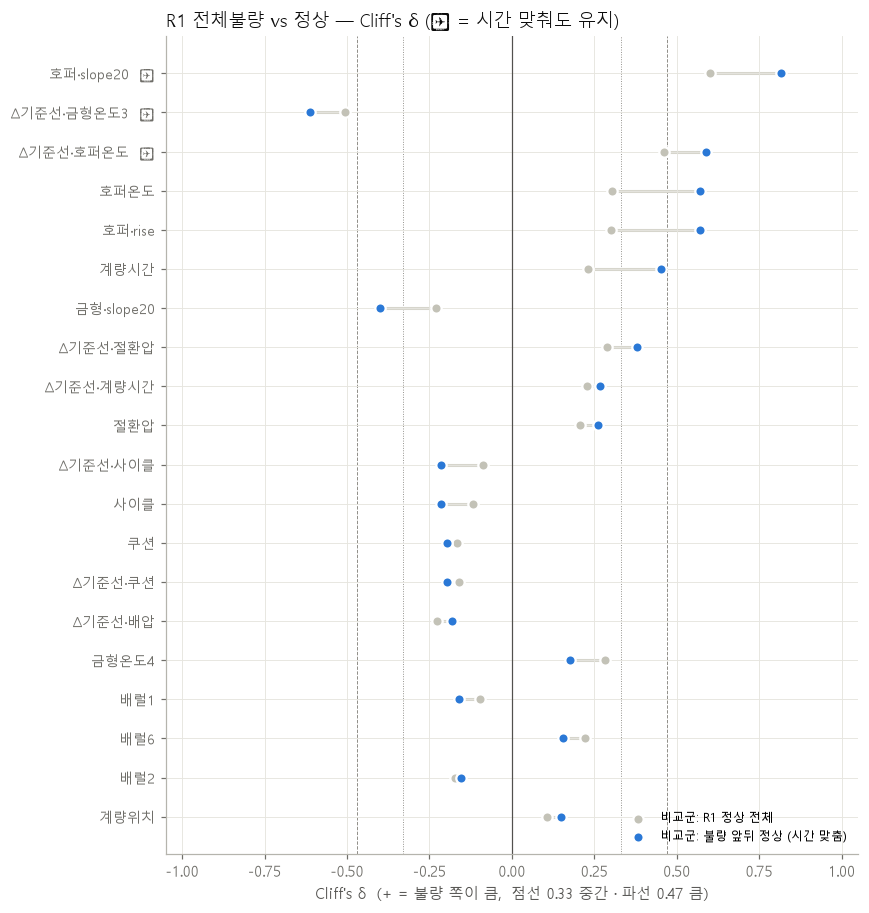

c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\r1_compare.py:160: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Malgun Gothic.
  fig.tight_layout()
c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\r1_compare.py:162: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Malgun Gothic.
  fig.savefig(save)
c:\anaconda\envs\kamp\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


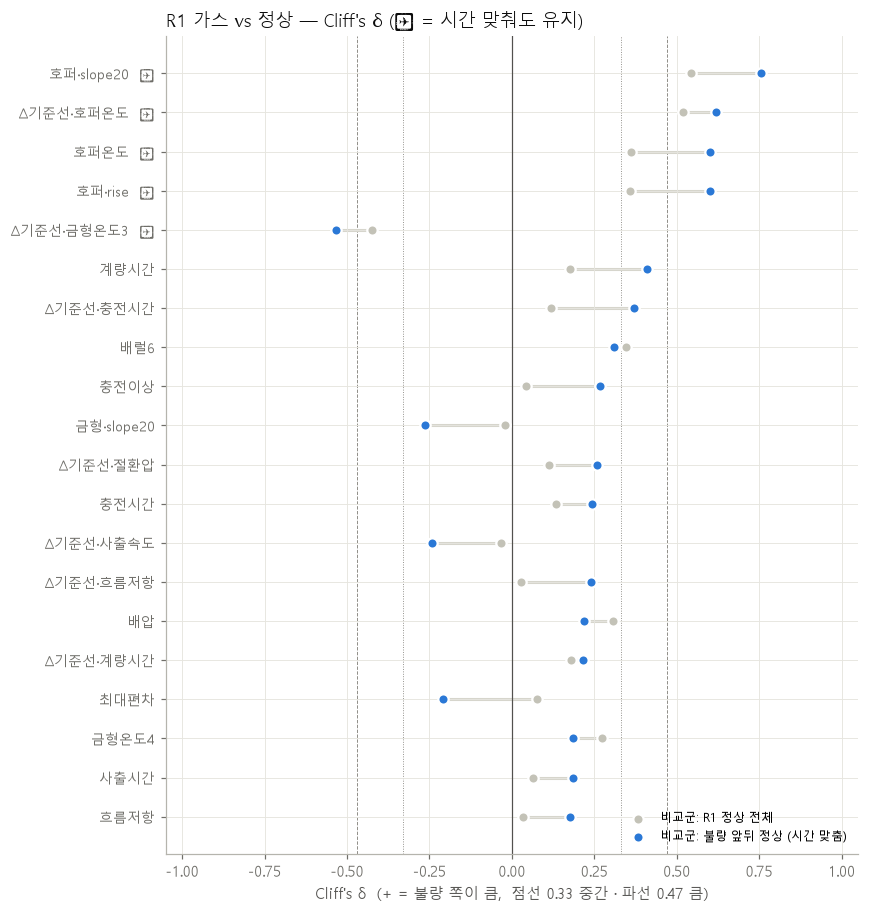

c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\r1_compare.py:160: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Malgun Gothic.
  fig.tight_layout()
c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\r1_compare.py:162: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Malgun Gothic.
  fig.savefig(save)
c:\anaconda\envs\kamp\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


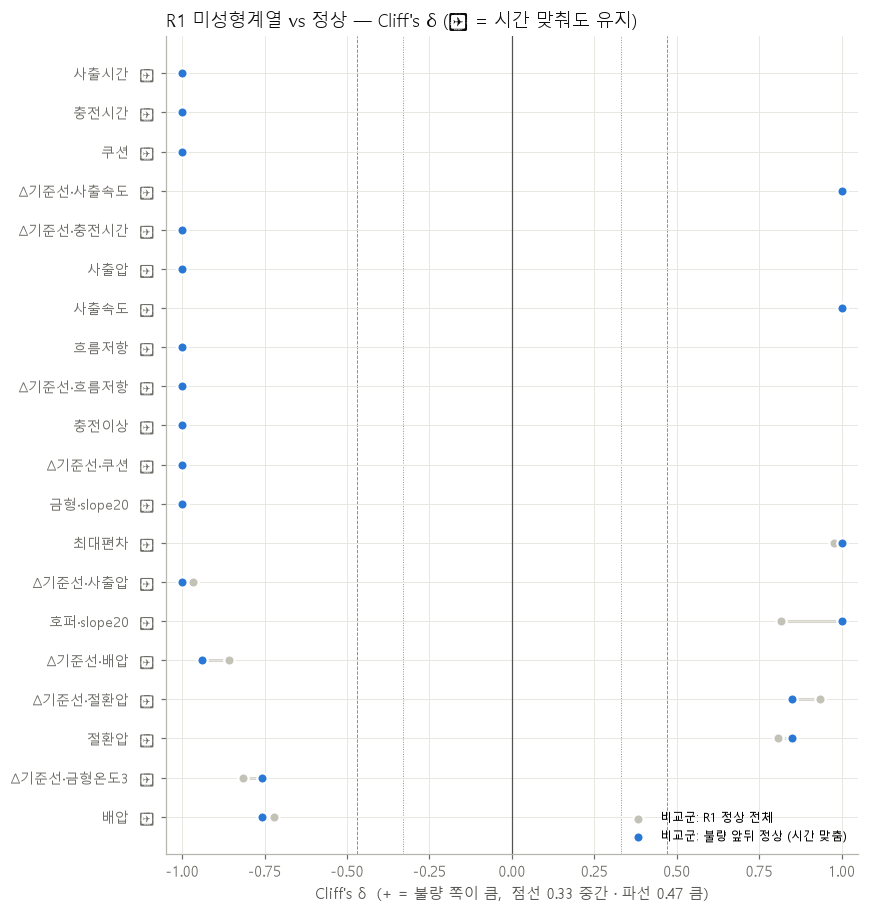

In [3]:
for g, t in TABLES.items():
    plot_effects(t, top=20, title=f"R1 {g} vs 정상 — Cliff's δ (✓ = 시간 맞춰도 유지)",
                 save=f'{OUT}/effects_{g}.png')

## 3. 타임라인 — 불량이 '추세 위'에 있는지, '순간적으로 튀는지'

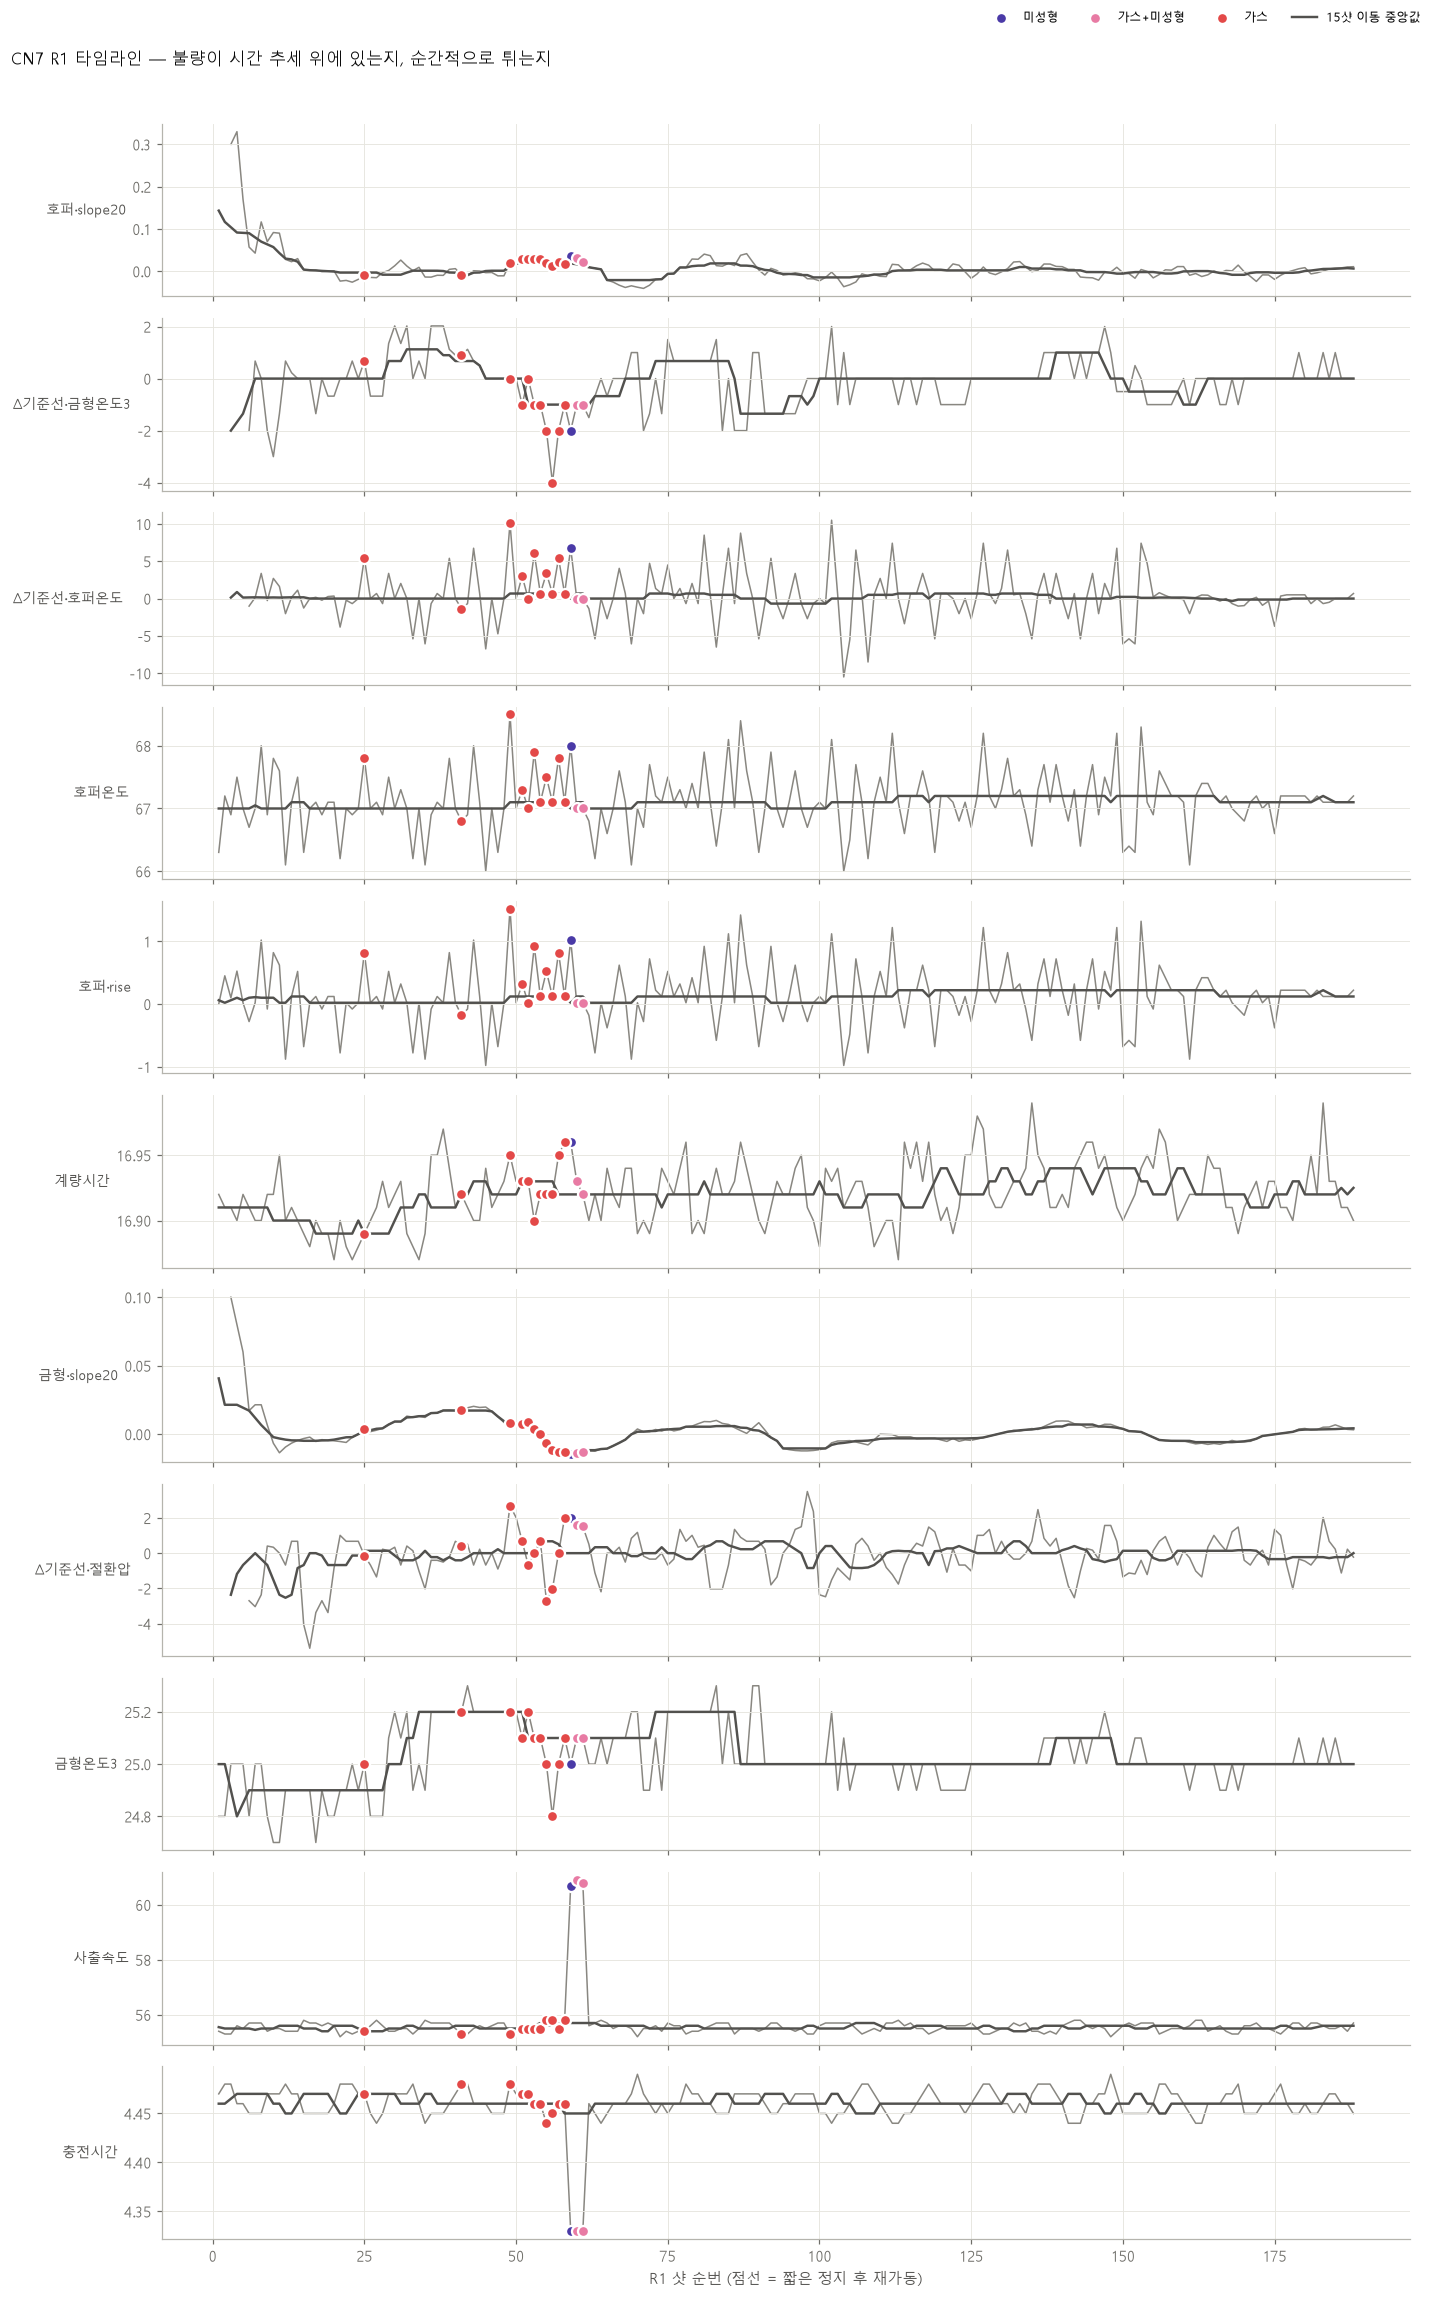

In [4]:
# 시간 맞춤 효과가 큰 변수 상위 8개 (전체불량 기준) + 금형온도는 항상 포함
top = TABLES['전체불량']['변수'].head(8).tolist()
for must in ['Mold_Temperature_3_raw', 'Max_Injection_Speed_raw', 'Filling_Time_raw']:
    if must not in top:
        top.append(must)
plot_timeline(R1, top, save=f'{OUT}/timeline.png')

## 4. 분포 — 정상 전체 / 시간 맞춘 정상 / 가스 / 미성형계열

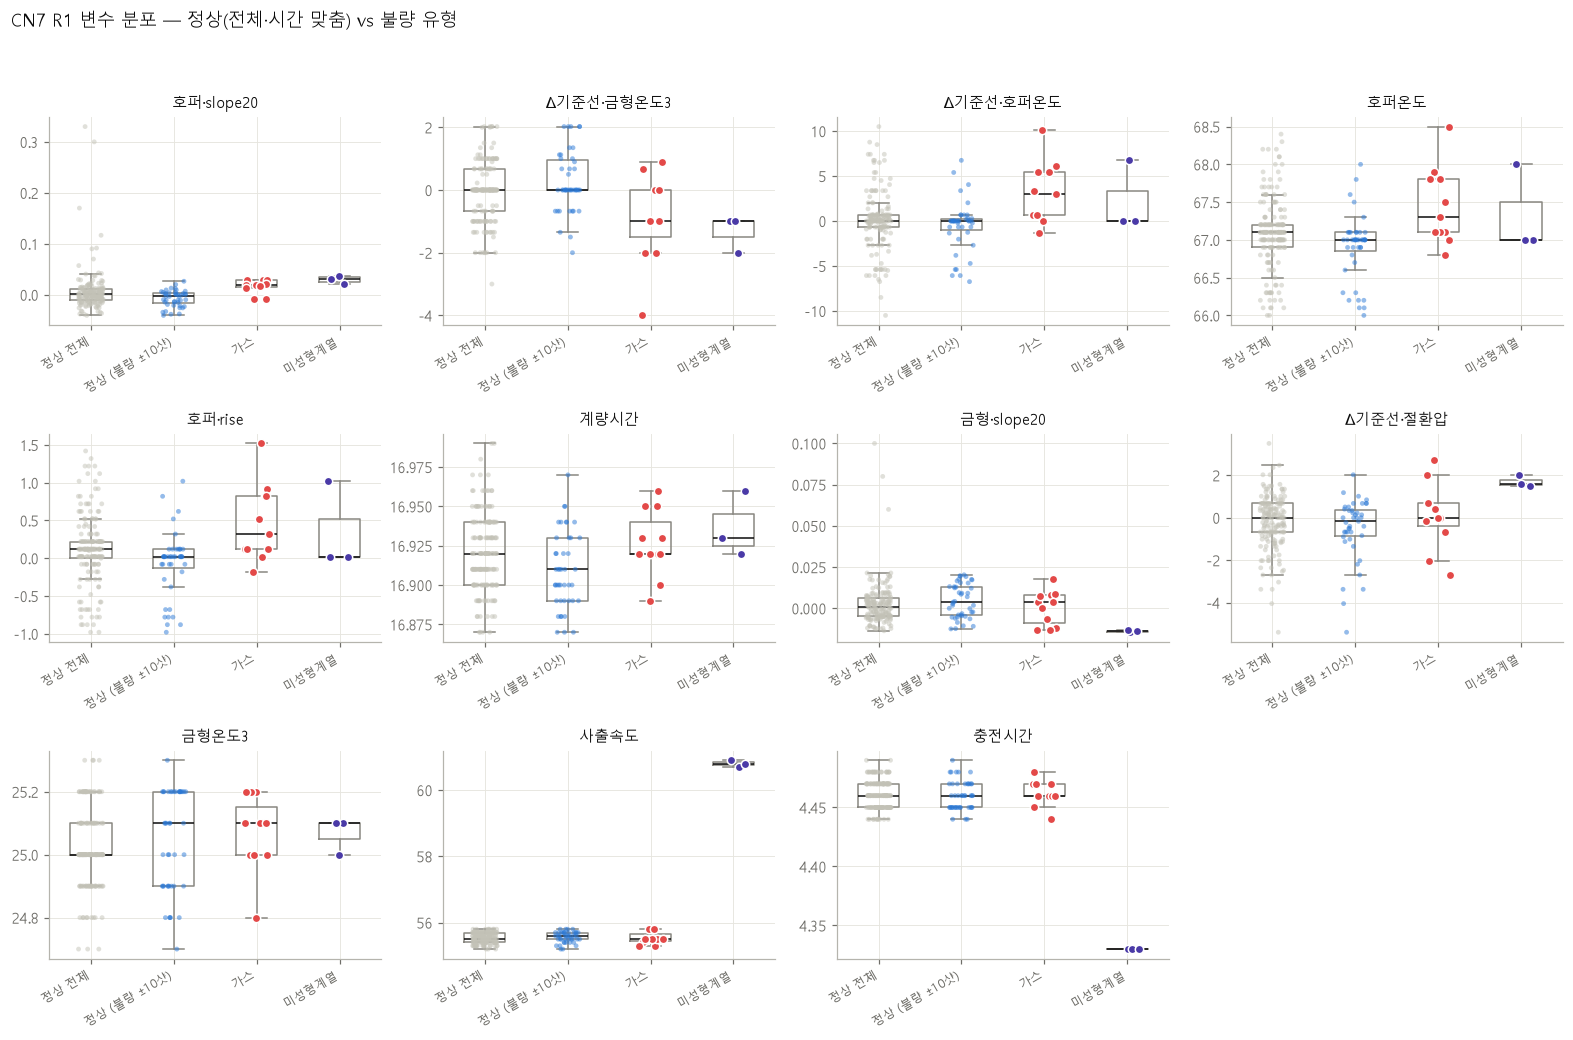

In [5]:
plot_distributions(R1, top, window=WINDOW, save=f'{OUT}/distributions.png')

## 5. Run 맥락 — R1 정상 샷 자체가 다른 Run과 다른가 (= Run 특성형)
R1 상자 전체가 다른 Run과 떨어져 있으면 그 변수는 **R1이라서** 다른 것 → 가스가 'Run 상태' 문제라는 근거.
R1 상자는 다른 Run과 비슷한데 불량 점만 튀면 **이벤트형**.

,변수,이름,R1_정상_med,다른Run_정상_med,diff_IQR,cliffs_delta(R1-다른Run)
6,Plasticizing_Position_raw,계량위치,68.840,68.480,2.250,1.000
20,Mold_Temperature_4_raw,금형온도4,27.600,23.300,2.688,1.000
19,Mold_Temperature_3_raw,금형온도3,25.000,22.000,1.875,1.000
11,Average_Back_Pressure_raw,배압,59.100,59.600,-1.667,-0.900
5,Cushion_Position_raw,쿠션,653.410,653.430,-1.000,-0.879
33,mold_rise,금형·rise,0.080,1.660,-0.963,-0.879
9,Max_Injection_Pressure_raw,사출압,141.700,141.900,-0.667,-0.609
2,Plasticizing_Time_raw,계량시간,16.920,16.830,0.310,0.408
4,Clamp_Close_Time_raw,형체시간,7.120,7.120,NaN,0.347
34,hopper_rise,호퍼·rise,0.120,0.420,-0.250,-0.306


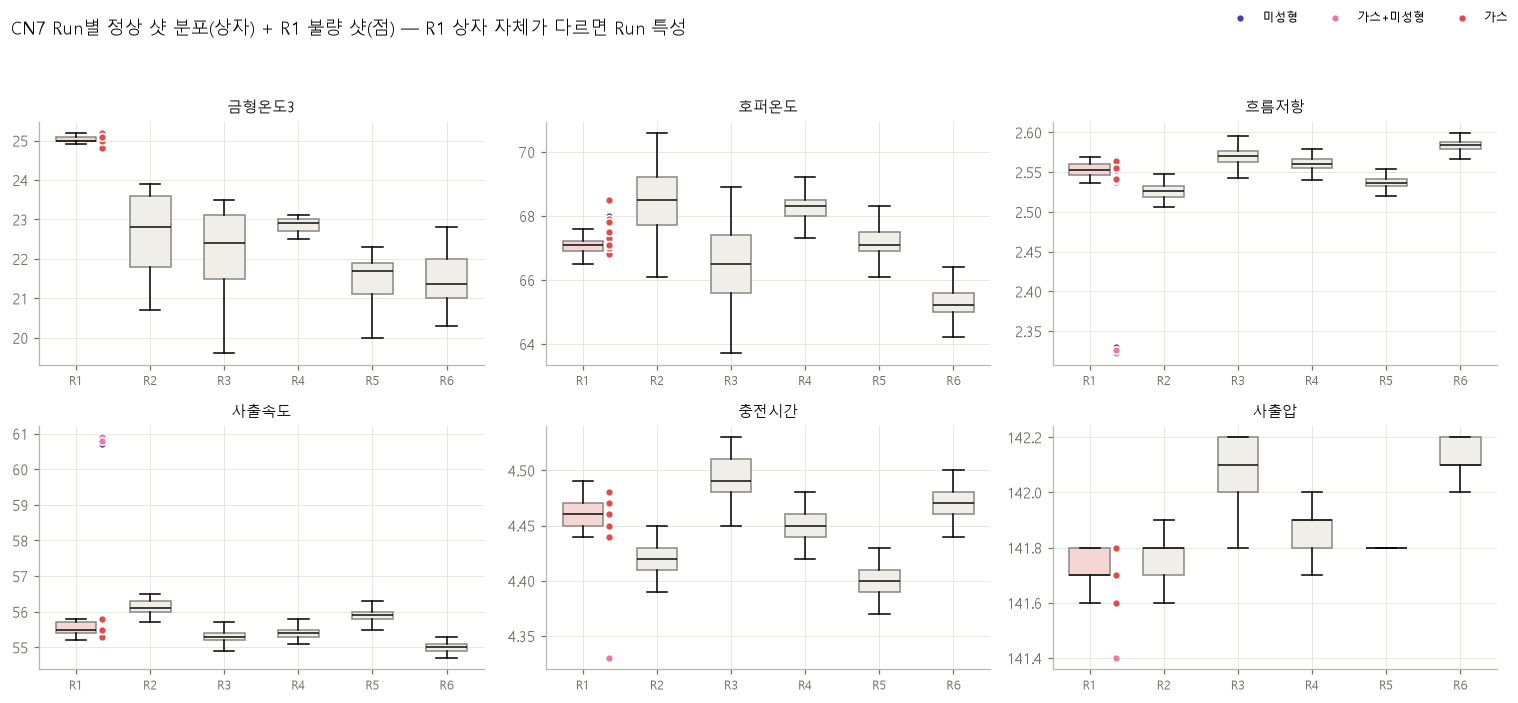

In [6]:
CTX = run_context_table(D, COLS)
CTX.to_csv(f'{OUT}/run_context.csv', index=False, encoding='utf-8-sig')
display(CTX.head(15).round(3))
ctx_vars = ['Mold_Temperature_3_raw', 'Hopper_Temperature_raw', 'flow_res',
            'Max_Injection_Speed_raw', 'Filling_Time_raw', 'Max_Injection_Pressure_raw']
plot_run_context(D, [c for c in ctx_vars if c in D.columns], save=f'{OUT}/run_context.png')

## 6. 해석 체크리스트
- ✓ 표시 변수 = 불량 특성 후보. 시간 맞춤에서 사라진 변수 = **시간 추세 때문에 달라 보였던 것**
- `diff_step`이 1~2칸 → 기록 해상도 수준 차이, 의미 약함
- 가스: ✓ 변수가 거의 없고 5번에서 R1 상자 자체가 다르면 → **Run 상태형** (샷 단위 예측 한계의 근거)
- 미성형계열: 속도↑·충전↓ 같은 ✓ 변수가 있으면 → **이벤트형** (이상탐지로 잡히는 이유)
- q_FDR은 참고만 (n=14). 결론은 효과크기 + 그래프로